# Titanic - Machine Learning from Disaster (v2)

**Goal:** predict passenger survival.

**Pipeline:** load data -> EDA -> advanced feature engineering -> model comparison (repeated cross-validation) -> soft-voting ensemble -> hold-out evaluation -> submission.


In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score, RepeatedStratifiedKFold, train_test_split
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

## 1. Load the data

In [2]:
# Find train.csv / test.csv on Kaggle or in the current folder
candidates = ['/kaggle/input/competitions/titanic', '/kaggle/input/titanic', '.']
data_dir = next(d for d in candidates if os.path.exists(os.path.join(d, 'train.csv')))
print('Using data from:', data_dir)

train_data = pd.read_csv(os.path.join(data_dir, 'train.csv'))
test_data = pd.read_csv(os.path.join(data_dir, 'test.csv'))
print('Train:', train_data.shape, '| Test:', test_data.shape)
train_data.head()

Using data from: /kaggle/input/competitions/titanic
Train: (891, 12) | Test: (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Exploratory data analysis

In [3]:
missing = pd.DataFrame({'train_missing': train_data.isna().sum(), 'test_missing': test_data.isna().sum()})
print(missing[missing.sum(axis=1) > 0])
print('\nOverall survival rate: {:.1%}'.format(train_data['Survived'].mean()))
print('\nSurvival by sex:\n', train_data.groupby('Sex')['Survived'].mean().map('{:.1%}'.format))
print('\nSurvival by class:\n', train_data.groupby('Pclass')['Survived'].mean().map('{:.1%}'.format))

          train_missing  test_missing
Age                 177          86.0
Cabin               687         327.0
Embarked              2           0.0
Fare                  0           1.0

Overall survival rate: 38.4%

Survival by sex:
 Sex
female    74.2%
male      18.9%
Name: Survived, dtype: object

Survival by class:
 Pclass
1    63.0%
2    47.3%
3    24.2%
Name: Survived, dtype: object


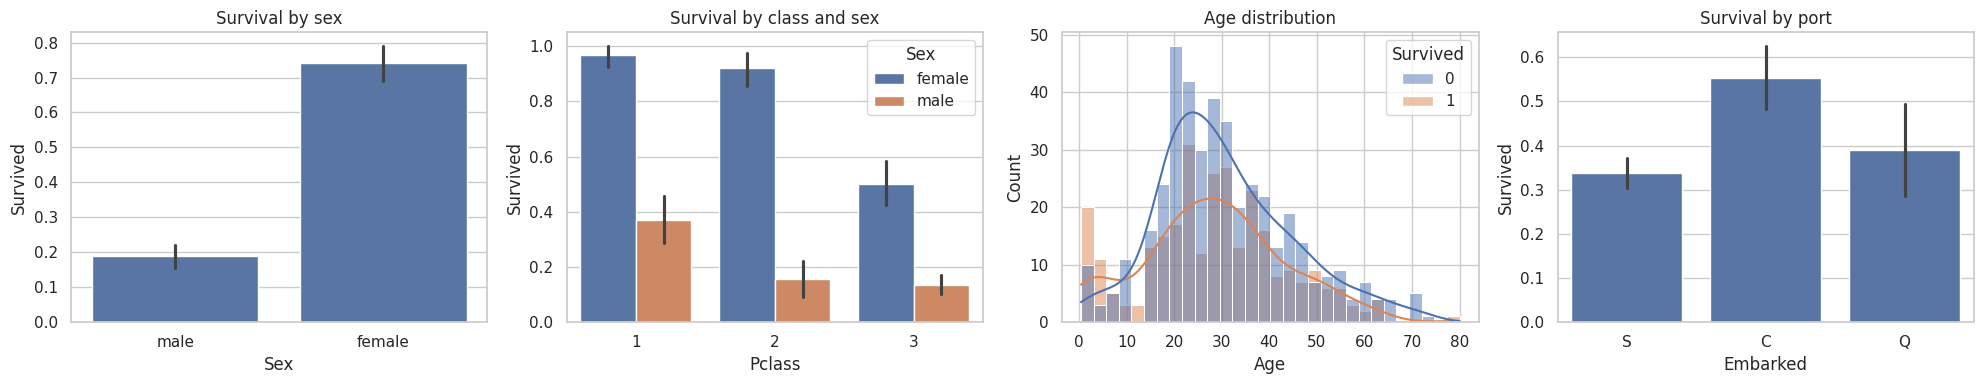

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
sns.barplot(data=train_data, x='Sex', y='Survived', ax=axes[0]); axes[0].set_title('Survival by sex')
sns.barplot(data=train_data, x='Pclass', y='Survived', hue='Sex', ax=axes[1]); axes[1].set_title('Survival by class and sex')
sns.histplot(data=train_data, x='Age', hue='Survived', bins=30, kde=True, ax=axes[2]); axes[2].set_title('Age distribution')
sns.barplot(data=train_data, x='Embarked', y='Survived', ax=axes[3]); axes[3].set_title('Survival by port')
plt.tight_layout(); plt.show()

**Observations:** women survived far more often than men; first class did better than third; children had better odds; Age, Cabin and Embarked have missing values.

## 3. Feature engineering

| Feature | Idea |
|---|---|
| Title | Mr / Mrs / Miss / Master / Rare, taken from the name |
| Age (filled) | median age of the same Title and Pclass instead of one global median |
| IsChild | age under 13 |
| FamilySize, IsAlone | SibSp + Parch + 1, and whether it equals 1 |
| TicketGroup | how many passengers share the same ticket |
| GroupSize, SmallGroup | largest of family/ticket group, and whether the group has 2-4 people (small groups survived best) |
| FarePerPerson | Fare divided by ticket group size |
| Deck | first letter of Cabin (B, C, D, E, Other) |
| HasCabin | whether a cabin was recorded |

These features use no survival labels, so they cannot leak the answer.

In [5]:
n_train = len(train_data)
full = pd.concat([train_data.drop(columns='Survived'), test_data], ignore_index=True)

def engineer(df):
    df = df.copy()
    df['Title'] = df['Name'].str.extract(r',\s*([^\.]+)\.', expand=False).str.strip()
    df['Title'] = df['Title'].replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})
    df['Title'] = df['Title'].where(df['Title'].isin(['Mr', 'Mrs', 'Miss', 'Master']), 'Rare')
    df['Age'] = df['Age'].fillna(df.groupby(['Title', 'Pclass'])['Age'].transform('median'))
    df['Age'] = df['Age'].fillna(df['Age'].median())
    df['IsChild'] = (df['Age'] < 13).astype(int)
    df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
    df['IsAlone'] = (df['FamilySize'] == 1).astype(int)
    df['TicketGroup'] = df.groupby('Ticket')['Ticket'].transform('count')
    df['GroupSize'] = df[['FamilySize', 'TicketGroup']].max(axis=1)
    df['SmallGroup'] = df['GroupSize'].between(2, 4).astype(int)
    df['FarePerPerson'] = df['Fare'] / df['TicketGroup']
    df['HasCabin'] = df['Cabin'].notna().astype(int)
    df['Deck'] = df['Cabin'].str[0].fillna('U')
    df['Deck'] = df['Deck'].where(df['Deck'].isin(['B', 'C', 'D', 'E']), 'Other')
    return df

fe = engineer(full)
numeric_features = ['Pclass', 'Age', 'Fare', 'FarePerPerson', 'FamilySize', 'TicketGroup',
                    'GroupSize', 'IsAlone', 'IsChild', 'SmallGroup', 'HasCabin']
categorical_features = ['Sex', 'Embarked', 'Title', 'Deck']

X = fe.iloc[:n_train][numeric_features + categorical_features]
X_test = fe.iloc[n_train:][numeric_features + categorical_features]
y = train_data['Survived']

preprocessor = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), numeric_features),
    ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore'))]), categorical_features)
])
print('Features used:', X.shape[1])
print(fe.iloc[:n_train].assign(Survived=y).groupby('SmallGroup')['Survived'].mean().round(3))

Features used: 15
SmallGroup
0    0.271
1    0.553
Name: Survived, dtype: float64


## 4. Model comparison (5-fold x 3 repeats cross-validation)

Logistic Regression  0.8260 (+/- 0.0206)
Random Forest        0.8309 (+/- 0.0148)
Gradient Boosting    0.8380 (+/- 0.0149)
SVM                  0.8268 (+/- 0.0261)
Voting Ensemble      0.8339 (+/- 0.0204)


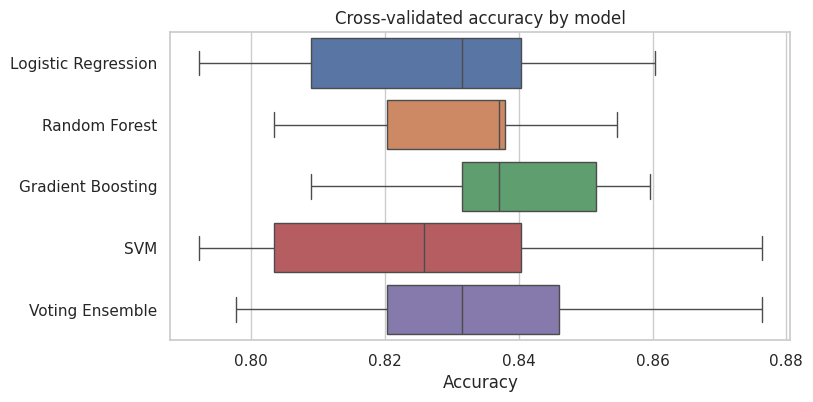

In [6]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

base_models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, C=0.5),
    'Random Forest': RandomForestClassifier(n_estimators=400, max_depth=6, min_samples_leaf=2, random_state=RANDOM_STATE),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=150, max_depth=3, learning_rate=0.05,
                                                    subsample=0.8, random_state=RANDOM_STATE),
    'SVM': SVC(C=1.0, gamma='scale', probability=True, random_state=RANDOM_STATE),
}
models = dict(base_models)
models['Voting Ensemble'] = VotingClassifier(list(base_models.items()), voting='soft')

results = {}
for name, clf in models.items():
    pipe = Pipeline([('prep', preprocessor), ('model', clf)])
    scores = cross_val_score(pipe, X, y, cv=cv, scoring='accuracy', n_jobs=-1)
    results[name] = scores
    print(f'{name:20s} {scores.mean():.4f} (+/- {scores.std():.4f})')

plt.figure(figsize=(8, 4))
sns.boxplot(data=pd.DataFrame(results), orient='h')
plt.title('Cross-validated accuracy by model'); plt.xlabel('Accuracy'); plt.show()

## 5. Final model: soft-voting ensemble

Averaging the predicted probabilities of four different models is more stable than relying on one model, which matters on a small dataset.

Hold-out accuracy: 0.8268

              precision    recall  f1-score   support

        Died       0.86      0.86      0.86       110
    Survived       0.78      0.77      0.77        69

    accuracy                           0.83       179
   macro avg       0.82      0.82      0.82       179
weighted avg       0.83      0.83      0.83       179



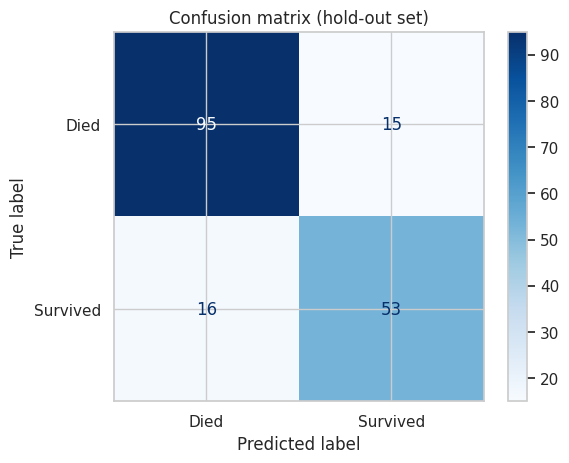

In [7]:
X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

final_model = Pipeline([('prep', preprocessor), ('model', models['Voting Ensemble'])])
final_model.fit(X_tr, y_tr)
val_pred = final_model.predict(X_val)

print('Hold-out accuracy: {:.4f}\n'.format(accuracy_score(y_val, val_pred)))
print(classification_report(y_val, val_pred, target_names=['Died', 'Survived']))
ConfusionMatrixDisplay.from_predictions(y_val, val_pred, display_labels=['Died', 'Survived'], cmap='Blues')
plt.title('Confusion matrix (hold-out set)'); plt.show()

## 6. Feature importance (Random Forest view)

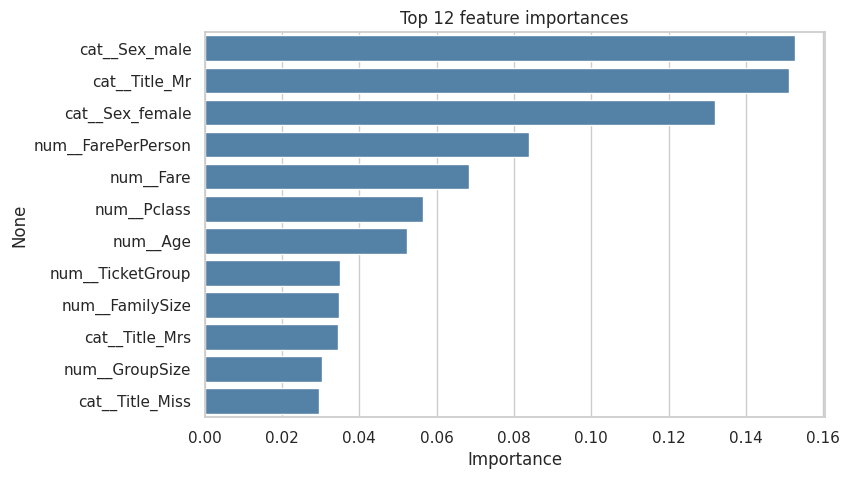

In [8]:
rf_pipe = Pipeline([('prep', preprocessor), ('model', base_models['Random Forest'])]).fit(X, y)
names = rf_pipe.named_steps['prep'].get_feature_names_out()
imp = pd.Series(rf_pipe.named_steps['model'].feature_importances_, index=names).sort_values(ascending=False).head(12)

plt.figure(figsize=(8, 5))
sns.barplot(x=imp.values, y=imp.index, color='steelblue')
plt.title('Top 12 feature importances'); plt.xlabel('Importance'); plt.show()

## 7. Train on all data and create the submission

In [9]:
final_model.fit(X, y)
predictions = final_model.predict(X_test)

output = pd.DataFrame({'PassengerId': test_data['PassengerId'], 'Survived': predictions})
output.to_csv('submission.csv', index=False)
print('Saved submission.csv', output.shape, '| predicted survival rate: {:.1%}'.format(output['Survived'].mean()))
output.head()

Saved submission.csv (418, 2) | predicted survival rate: 39.2%


,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1
